**Nom et prénom :** Tiamani Hiba **Code Apogée :** 23008995 **Groupe :** 3
**Filière :** S7 FIN **Date :** 17/11/2026
**Dépôt GitHub :** https://github.com/tiamani-hibaencg-pixel/23008995-Tiamanihiba-Fin3.git

## 1. Sujet et problématique
- **Intérêt du sujet** : Les investisseurs et les gérants de portefeuille veulent comprendre pourquoi certaines actions rapportent plus que d'autres. Le modèle de Fama-French explique les rendements par trois facteurs de risque : le marché, la taille de l'entreprise et sa « valeur ». En mesurant l'exposition d'un portefeuille à ces facteurs, on peut juger si sa performance vient du risque pris ou d'un vrai talent du gérant (l'« alpha »). Le résultat sert à évaluer des gérants et à construire des portefeuilles.
- **Problématique** : Le modèle à trois facteurs de Fama-French explique-t-il mieux les rendements mensuels de 25 portefeuilles (classés par taille et par valeur) que le CAPM et que la simple moyenne historique, et les alphas de ces 25 portefeuilles sont-ils conjointement nuls ?
- **Objectif mesurable** : Métrique principale : R² hors échantillon, calculé par rapport à la référence naïve (la moyenne de l'apprentissage), moyenné sur les 25 portefeuilles. Référence : moyenne historique des rendements excédentaires (et CAPM en comparaison). Période de test : de 2010-01 à la dernière date disponible, après un apprentissage de 1963-07 à 2009-12. Seuil de réussite : R² hors échantillon supérieur à 0,80 pour le modèle à trois facteurs. Test conjoint des alphas nuls (test GRS) au seuil de 5 %. Seuils fixés avant de voir les résultats de test.
- **Nature du problème** : Régression linéaire multiple. La variable à prédire (le rendement excédentaire d'un portefeuille) est continue, d'où une régression et non une classification. Les données sont une série temporelle mensuelle, donc le découpage sera chronologique. Le modèle est ajusté 25 fois, une par portefeuille.
- **Algorithme principal envisagé** : n°1 de l'annexe A, régression linéaire (LinearRegression).

In [3]:
!pip install -q pandas-datareader statsmodels

import sys
from pathlib import Path
from datetime import date
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import sklearn
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score   # utilisés dans le cours
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit

GRAINE = 42                 # comme dans le support
np.random.seed(GRAINE)

# Crée les dossiers du dépôt (chemins relatifs)
for d in ["data/raw", "data/processed", "figures", "rapport", "presentation", "docs"]:
    Path(d).mkdir(parents=True, exist_ok=True)

print("Python", sys.version.split()[0])
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

Python 3.13.18
numpy 2.4.6 | pandas 2.2.3 | scikit-learn 1.6.1


## 2. Jeu de données

In [4]:
f_ports = Path("data/raw/25_portfolios_5x5.csv")
f_ff = Path("data/raw/ff_3_factors.csv")

def lire_french(url):
    """Plan B : lit directement le fichier CSV zippé du site de Kenneth French (1er tableau = mensuel)."""
    import requests, zipfile, io
    z = zipfile.ZipFile(io.BytesIO(requests.get(url, timeout=60).content))
    lignes = z.read(z.namelist()[0]).decode('latin-1').splitlines()
    i = next(k for k, l in enumerate(lignes)
             if l.split(',')[0].strip().isdigit() and len(l.split(',')[0].strip()) == 6)
    colonnes = ['date'] + [c.strip() for c in lignes[i - 1].split(',')[1:]]
    lignes_data = []
    for l in lignes[i:]:
        p = [x.strip() for x in l.split(',')]
        if not (p[0].isdigit() and len(p[0]) == 6):
            break
        lignes_data.append(p)
    df = pd.DataFrame(lignes_data, columns=colonnes)
    df['date'] = pd.to_datetime(df['date'], format='%Y%m')
    return df.set_index('date').astype(float).loc['1963-07-01':]

if f_ports.exists() and f_ff.exists():
    ports = pd.read_csv(f_ports, index_col=0, parse_dates=True)
    ff = pd.read_csv(f_ff, index_col=0, parse_dates=True)
    print("Données lues depuis data/raw/")
else:
    try:
        from pandas_datareader import data as web
        ports = web.DataReader('25_Portfolios_5x5', 'famafrench', start='1963-07')[0]
        ff = web.DataReader('F-F_Research_Data_Factors', 'famafrench', start='1963-07')[0]
        ports.index = ports.index.to_timestamp()
        ff.index = ff.index.to_timestamp()
        print("Téléchargé avec pandas_datareader")
    except Exception as e:
        print("pandas_datareader a échoué (", type(e).__name__, "), plan B : téléchargement direct")
        base = "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/"
        ports = lire_french(base + "25_Portfolios_5x5_CSV.zip")
        ff = lire_french(base + "F-F_Research_Data_Factors_CSV.zip")
    ports.to_csv(f_ports)
    ff.to_csv(f_ff)
    print("Extraction du", date.today(), "enregistrée dans data/raw/")

# Fama-French code les valeurs manquantes par -99.99 ou -999
ports = ports.replace([-99.99, -999], np.nan)
ff = ff.replace([-99.99, -999], np.nan)

Téléchargé avec pandas_datareader
Extraction du 2026-11-17 enregistrée dans data/raw/


In [5]:
print("=== Portefeuilles ===")
print("Dimensions :", ports.shape, "(lignes = mois, colonnes = portefeuilles)")
print("Période    :", ports.index.min().date(), "->", ports.index.max().date())
print("Types      :", ports.dtypes.value_counts().to_dict())
print("Manquants  :", int(ports.isna().sum().sum()))
print("Doublons de dates :", int(ports.index.duplicated().sum()))

print("\n=== Facteurs ===")
print("Dimensions :", ff.shape)
print("Colonnes   :", list(ff.columns))
print("Période    :", ff.index.min().date(), "->", ff.index.max().date())
print("Types      :", ff.dtypes.value_counts().to_dict())
print("Manquants  :", int(ff.isna().sum().sum()))

# Fréquence : écart entre deux dates consécutives (doit être ~ 1 mois)
ecarts = ports.index.to_series().diff().dt.days.dropna()
print("\nÉcart entre dates (jours) : min", int(ecarts.min()), "| max", int(ecarts.max()), "-> fréquence mensuelle")
print("Date d'extraction :", date.today())

print("\nPremières lignes des portefeuilles (5 premières colonnes) :")
display(ports.iloc[:3, :5])
print("Premières lignes des facteurs :")
display(ff.head(3))

=== Portefeuilles ===
Dimensions : (759, 25) (lignes = mois, colonnes = portefeuilles)
Période    : 1963-07-01 -> 2026-09-01
Types      : {dtype('float64'): 25}
Manquants  : 0
Doublons de dates : 0

=== Facteurs ===
Dimensions : (759, 4)
Colonnes   : ['Mkt-RF', 'SMB', 'HML', 'RF']
Période    : 1963-07-01 -> 2026-09-01
Types      : {dtype('float64'): 4}
Manquants  : 0

Écart entre dates (jours) : min 28 | max 31 -> fréquence mensuelle
Date d'extraction : 2026-11-17

Premières lignes des portefeuilles (5 premières colonnes) :


,SMALL LoBM,ME1 BM2,ME1 BM3,ME1 BM4,SMALL HiBM
Date,,,,,
1963-07-01,1.1287,-0.3632,0.7223,-0.0413,-1.2447
1963-08-01,4.2396,1.3730,1.4917,2.5068,4.6644
1963-09-01,-1.7343,0.6204,-1.0007,-1.5215,-0.3584


Premières lignes des facteurs :


,Mkt-RF,SMB,HML,RF
Date,,,,
1963-07-01,-0.39,-0.57,-0.84,0.27
1963-08-01,5.08,-0.95,1.72,0.25
1963-09-01,-1.57,-0.25,-0.02,0.27


In [6]:
manq_ports = ports.isna().mean().mul(100).round(2)
manq_ff = ff.isna().mean().mul(100).round(2)
print("Manquants (%) par portefeuille : max =", manq_ports.max(), "| moyenne =", round(manq_ports.mean(), 2))
print("Manquants (%) par facteur :")
print(manq_ff)
print("\nNombre de mois :", len(ports))
print("Les 25 portefeuilles :", list(ports.columns))

Manquants (%) par portefeuille : max = 0.0 | moyenne = 0.0
Manquants (%) par facteur :
Mkt-RF    0.0
SMB       0.0
HML       0.0
RF        0.0
dtype: float64

Nombre de mois : 759
Les 25 portefeuilles : ['SMALL LoBM', 'ME1 BM2', 'ME1 BM3', 'ME1 BM4', 'SMALL HiBM', 'ME2 BM1', 'ME2 BM2', 'ME2 BM3', 'ME2 BM4', 'ME2 BM5', 'ME3 BM1', 'ME3 BM2', 'ME3 BM3', 'ME3 BM4', 'ME3 BM5', 'ME4 BM1', 'ME4 BM2', 'ME4 BM3', 'ME4 BM4', 'ME4 BM5', 'BIG LoBM', 'ME5 BM2', 'ME5 BM3', 'ME5 BM4', 'BIG HiBM']


- **Source** : Kenneth R. French Data Library (Dartmouth College), https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html. Jeux utilisés : « 25 Portfolios Formed on Size and Book-to-Market (5 x 5) » (rendements mensuels pondérés par la capitalisation) et « Fama/French 3 Factors ». **Date d'extraction** : 17/11/2026.
- **Licence** : aucune condition précise n'est indiquée sur la page de la source. *(Vérifie sur la page avant d'écrire ça : si tu vois une mention de licence, recopie-la à la place.)*
- **Taille** : 759 mois, de juillet 1963 à septembre 2026, fréquence mensuelle. 25 portefeuilles et 4 séries de facteurs (Mkt-RF, SMB, HML, RF).
- **Unité d'observation** : une ligne représente un mois.
- **Variable cible** : le rendement excédentaire du portefeuille, construit comme rendement du portefeuille − RF (taux sans risque).
- **Adéquation** : ces 25 portefeuilles et ces trois facteurs sont exactement ceux avec lesquels le modèle de Fama-French a été conçu, ce qui permet de répondre directement à la problématique.
- **Limites** : actions américaines uniquement ; rendements pondérés par la capitalisation (les grandes entreprises pèsent plus dans chaque portefeuille) ; séries recalculées et mises à jour par les auteurs, donc révisions possibles ; changements de régime (crises de 2000, 2008, 2020) ; résultats dépendants de la période choisie.

| Variable | Description | Type | Unité | Rôle | Manquants (%) |
|---|---|---|---|---|---|
| SMALL LoBM, ME1 BM2, …, ME5 BM4, BIG HiBM (25 colonnes) | Rendement mensuel de chaque portefeuille classé par taille (ME, de 1 = petites à 5 = grandes) et par ratio valeur comptable / valeur de marché (BM, de 1 = croissance à 5 = valeur) | numérique | % par mois | cible (après retrait de RF) | 0 |
| Mkt-RF | Rendement du marché américain moins le taux sans risque | numérique | % par mois | explicative | 0 |
| SMB | Rendement des petites entreprises moins celui des grandes (effet taille) | numérique | % par mois | explicative | 0 |
| HML | Rendement des titres de valeur moins celui des titres de croissance (effet valeur) | numérique | % par mois | explicative | 0 |
| RF | Taux sans risque mensuel | numérique | % par mois | sert à construire la cible | 0 |
| Y (créée) | Y = rendement du portefeuille − RF | numérique | % par mois | cible | 0 (calculée à partir de variables complètes) |
| Date | Mois d'observation (index) | date | mois | index | 0 |

**Interprétation.** Le jeu contient 759 mois, de juillet 1963 à septembre 2026, avec 0 valeur manquante et 0 doublon de dates : les données sont propres. Toutes les variables sont numériques (float64) et l'écart entre deux dates est de 28 à 31 jours, ce qui confirme une fréquence mensuelle régulière. Les rendements sont exprimés en pourcentage mensuel. La valeur −99.99, qui sert de code de donnée manquante chez Fama-French, n'a pas été rencontrée, donc aucune ligne n'a été supprimée ni imputée. Les données sont donc prêtes pour l'exploration.

## 3. Exploration
L'exploration porte uniquement sur la période d'apprentissage (1963-07 à 2009-12), pour ne pas utiliser d'information du jeu de test dans mes choix.

In [7]:
COLS3 = ['Mkt-RF', 'SMB', 'HML']
FIN_APPRENTISSAGE = '2009-12'

Y = ports.sub(ff['RF'], axis=0)              # rendement excédentaire = rendement - taux sans risque
Y_expl = Y.loc[:FIN_APPRENTISSAGE]           # exploration : apprentissage seulement
ff_expl = ff.loc[:FIN_APPRENTISSAGE]

print("Période explorée :", Y_expl.index.min().date(), "->", Y_expl.index.max().date(), "|", len(Y_expl), "mois")

Période explorée : 1963-07-01 -> 2009-12-01 | 558 mois


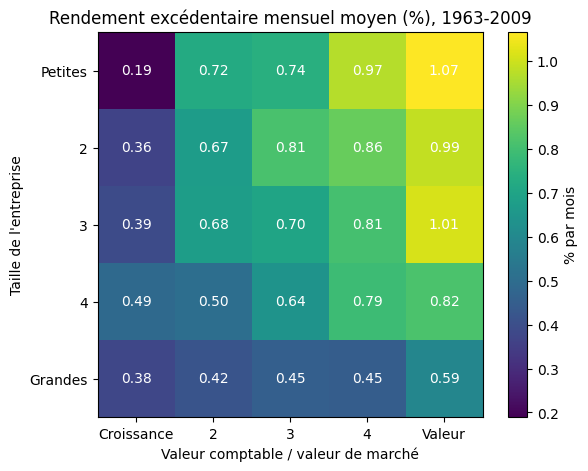

Plus élevé : SMALL HiBM 1.07 % par mois
Plus faible : SMALL LoBM 0.19 % par mois
Moyenne des 5 colonnes 'Croissance' : 0.36 | 'Valeur' : 0.89
Moyenne des 5 lignes 'Petites' : 0.74 | 'Grandes' : 0.46


In [8]:
moy = Y_expl.mean().values.reshape(5, 5)     # lignes = taille, colonnes = valeur

fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(moy, cmap='viridis')
ax.set_xticks(range(5)); ax.set_xticklabels(['Croissance', '2', '3', '4', 'Valeur'])
ax.set_yticks(range(5)); ax.set_yticklabels(['Petites', '2', '3', '4', 'Grandes'])
ax.set_xlabel("Valeur comptable / valeur de marché"); ax.set_ylabel("Taille de l'entreprise")
ax.set_title("Rendement excédentaire mensuel moyen (%), 1963-2009")
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{moy[i, j]:.2f}", ha='center', va='center', color='white')
plt.colorbar(im, label="% par mois")
plt.savefig("figures/fig1_heatmap.png", dpi=150, bbox_inches='tight')
plt.show()

m = Y_expl.mean()
print("Plus élevé :", m.idxmax(), round(m.max(), 2), "% par mois")
print("Plus faible :", m.idxmin(), round(m.min(), 2), "% par mois")
print("Moyenne des 5 colonnes 'Croissance' :", round(moy[:, 0].mean(), 2), "| 'Valeur' :", round(moy[:, 4].mean(), 2))
print("Moyenne des 5 lignes 'Petites' :", round(moy[0, :].mean(), 2), "| 'Grandes' :", round(moy[4, :].mean(), 2))

**Interprétation ** Le portefeuille au rendement excédentaire moyen le plus élevé est SMALL HiBM (petites entreprises de valeur) avec 1,07 % par mois, et le plus faible est SMALL LoBM (petites entreprises de croissance) avec 0,19 % par mois. Les portefeuilles de valeur (colonne de droite) rapportent en moyenne 0,89 % par mois contre 0,36 % pour ceux de croissance, et les petites entreprises 0,74 % contre 0,46 % pour les grandes. L'effet « valeur » est net et se retrouve sur les cinq lignes de taille : le rendement augmente de gauche à droite dans chacune. L'effet « taille » est visible surtout parmi les titres de valeur (1,07 % pour les petites contre 0,59 % pour les grandes), mais il s'inverse dans la colonne « croissance » (0,19 % pour les petites contre 0,38 % pour les grandes) : l'écart entre petites et grandes entreprises n'est donc pas uniforme. Ces résultats sont globalement cohérents avec les effets taille et valeur, ce qui justifie d'utiliser SMB et HML comme facteurs. Le cas des petites entreprises de croissance, très peu rentables, sera à surveiller dans l'analyse des erreurs, car un modèle linéaire à trois facteurs risque d'avoir du mal à l'expliquer.

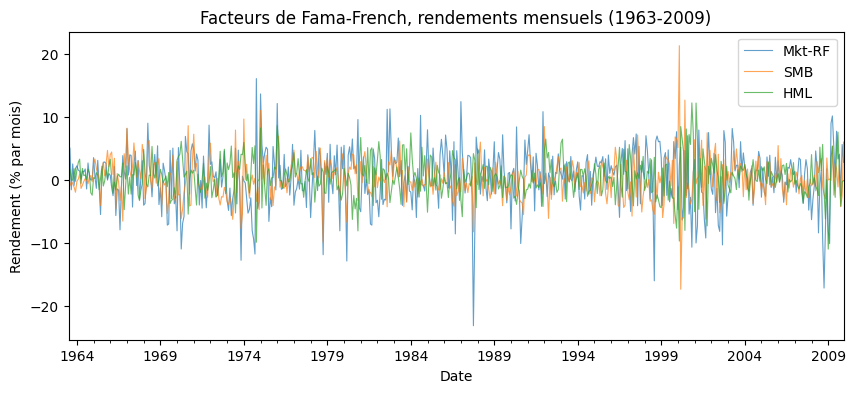

      Mkt-RF    SMB    HML
mean    0.43   0.23   0.42
std     4.50   3.17   2.86
min   -23.19 -17.39 -11.01
max    16.11  21.34  12.25

Trois pires mois du marché (Mkt-RF) :
Date
1987-10-01   -23.19
2008-10-01   -17.20
1998-08-01   -16.05
Name: Mkt-RF, dtype: float64


In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
ff_expl[COLS3].plot(ax=ax, alpha=0.7, linewidth=0.8)
ax.set_title("Facteurs de Fama-French, rendements mensuels (1963-2009)")
ax.set_xlabel("Date"); ax.set_ylabel("Rendement (% par mois)")
plt.savefig("figures/fig2_facteurs.png", dpi=150, bbox_inches='tight')
plt.show()

print(ff_expl[COLS3].describe().loc[['mean', 'std', 'min', 'max']].round(2))
print("\nTrois pires mois du marché (Mkt-RF) :")
print(ff_expl['Mkt-RF'].nsmallest(3).round(2))

**Interprétation ** Le facteur le plus volatil est Mkt-RF (écart-type de 4,50 % par mois), devant SMB (3,17 %) et HML (2,86 %). Les rendements moyens sont positifs pour les trois : 0,43 % par mois pour le marché, 0,23 % pour SMB et 0,42 % pour HML, soit bien moins que leur volatilité, donc les facteurs sont très bruités d'un mois à l'autre. Les trois pires mois du marché sont octobre 1987 (−23,19 %, krach boursier), octobre 2008 (−17,20 %, crise financière) et août 1998 (−16,05 %, crise russe et faillite du fonds LTCM). Le graphique montre aussi que la volatilité n'est pas constante : elle se concentre par périodes (autour de 1987, de 1998-2002 et de 2008-2009), et SMB et HML atteignent leurs valeurs extrêmes autour de 2000 (SMB de −17,39 % à +21,34 %), lors de la bulle internet. Je ne supprime pas ces valeurs : ce sont de vrais événements de marché, et les retirer sous-estimerait le risque que le modèle doit expliquer.

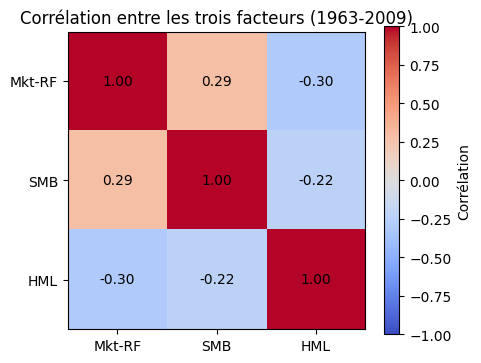

        Mkt-RF   SMB   HML
Mkt-RF    1.00  0.29 -0.30
SMB       0.29  1.00 -0.22
HML      -0.30 -0.22  1.00


In [10]:
corr = ff_expl[COLS3].corr()

fig, ax = plt.subplots(figsize=(4.8, 4))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(3)); ax.set_xticklabels(corr.columns)
ax.set_yticks(range(3)); ax.set_yticklabels(corr.columns)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha='center', va='center')
ax.set_title("Corrélation entre les trois facteurs (1963-2009)")
plt.colorbar(im, label="Corrélation")
plt.savefig("figures/fig3_correlation.png", dpi=150, bbox_inches='tight')
plt.show()
print(corr.round(2))

**Interprétation ** La corrélation la plus forte (en valeur absolue) est entre Mkt-RF et HML (−0,30), puis entre Mkt-RF et SMB (+0,29) ; la plus faible est entre SMB et HML (−0,22). Toutes les corrélations sont modérées (entre −0,30 et +0,29) : les facteurs sont donc peu corrélés entre eux, et chacun apporte une information distincte. Il n'y a pas de problème de multicolinéarité qui rendrait les coefficients instables (le seuil d'alerte est autour de 0,8 en valeur absolue). Le signe négatif entre le marché et HML signifie que les titres de valeur ont tendance à mieux se comporter quand le marché baisse, ce qui est typique de ce facteur.

In [11]:
print("Manquants (portefeuilles) :", int(Y_expl.isna().sum().sum()))
print("Manquants (facteurs)      :", int(ff_expl.isna().sum().sum()))
print("Doublons de dates          :", int(Y_expl.index.duplicated().sum()))

# Valeurs atypiques : mois à plus de 3 écarts-types de la moyenne
z = (ff_expl[COLS3] - ff_expl[COLS3].mean()) / ff_expl[COLS3].std()
print("Mois avec |z| > 3 par facteur :", (z.abs() > 3).sum().to_dict())
print("Valeur la plus basse de tous les portefeuilles :", round(Y_expl.min().min(), 2), "%")
print("Valeur la plus haute de tous les portefeuilles :", round(Y_expl.max().max(), 2), "%")

Manquants (portefeuilles) : 0
Manquants (facteurs)      : 0
Doublons de dates          : 0
Mois avec |z| > 3 par facteur : {'Mkt-RF': 4, 'SMB': 5, 'HML': 5}
Valeur la plus basse de tous les portefeuilles : -34.77 %
Valeur la plus haute de tous les portefeuilles : 43.36 %


**Qualité des données.**
- **Valeurs manquantes** : détection par `isna()` : 0 trouvée, ni dans les portefeuilles ni dans les facteurs. Décision : aucune imputation. Justification : il n'y a rien à corriger, et le code −99.99 n'apparaît pas.
- **Doublons** : détection par `index.duplicated()` : 0. Décision : aucune action.
- **Valeurs atypiques** : détection par le critère de plus de 3 écarts-types autour de la moyenne : 4 mois pour Mkt-RF, 5 pour SMB et 5 pour HML sur 558 mois (moins de 1 % des mois). Les valeurs extrêmes des portefeuilles vont de −34,77 % à +43,36 % par mois. Décision : conservées. Justification : en finance, une valeur extrême est souvent réelle (krach de 1987, crise de 2008, bulle internet) et fait partie du risque que le modèle doit expliquer ; les supprimer biaiserait les coefficients et ferait paraître le modèle meilleur qu'il n'est. La limite est que ces mois très agités peuvent peser lourd dans les moindres carrés.

## 4. Préparation

In [12]:
# 1) Dates communes aux deux fichiers (par sécurité)
common = ports.index.intersection(ff.index)
ports, ff = ports.loc[common], ff.loc[common]

# 2) Cible et variables explicatives
Y = ports.sub(ff['RF'], axis=0)       # rendement excédentaire
X = ff[COLS3]                         # Mkt-RF, SMB, HML

# 3) Découpage chronologique, SANS mélange aléatoire
Y_tr, Y_te = Y.loc[:'2009-12'], Y.loc['2010-01':]
X_tr, X_te = X.loc[:'2009-12'], X.loc['2010-01':]

assert Y_tr.index.max() < Y_te.index.min()        # le test est postérieur à l'apprentissage
assert (X_tr.index == Y_tr.index).all() and (X_te.index == Y_te.index).all()
assert not X.isna().any().any() and not Y.isna().any().any()

print("Apprentissage :", Y_tr.index.min().date(), "->", Y_tr.index.max().date(), "|", len(Y_tr), "mois")
print("Test          :", Y_te.index.min().date(), "->", Y_te.index.max().date(), "|", len(Y_te), "mois")

# 4) Preuve d'alignement : à la même date t, facteurs, rendement, RF et cible
p0 = ports.columns[0]
preuve = pd.concat([X.head(3),
                    ports[p0].head(3).rename(f"R({p0})"),
                    ff['RF'].head(3),
                    Y[p0].head(3).rename("Y = R - RF")], axis=1)
display(preuve)

# 5) Sauvegarde des données préparées
Y.to_csv("data/processed/rendements_excedentaires.csv")
X.to_csv("data/processed/facteurs.csv")

Apprentissage : 1963-07-01 -> 2009-12-01 | 558 mois
Test          : 2010-01-01 -> 2026-09-01 | 201 mois


,Mkt-RF,SMB,HML,R(SMALL LoBM),RF,Y = R - RF
Date,,,,,,
1963-07-01,-0.39,-0.57,-0.84,1.1287,0.27,0.8587
1963-08-01,5.08,-0.95,1.72,4.2396,0.25,3.9896
1963-09-01,-1.57,-0.25,-0.02,-1.7343,0.27,-2.0043


In [13]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

def nouveau_modele():
    """Pipeline : ici une seule étape (la régression). On pourrait y ajouter une
    imputation ou une standardisation : elles seraient alors ajustées sur l'apprentissage."""
    return Pipeline([('reg', LinearRegression())])

# Test de la chaîne : ajustement sur l'APPRENTISSAGE uniquement
essai = nouveau_modele().fit(X_tr, Y_tr)
print("Ajusté sur", len(X_tr), "mois d'apprentissage.")
print("Forme des coefficients appris (25 portefeuilles x 3 facteurs) :", essai.named_steps['reg'].coef_.shape)
print("Forme des alphas appris :", essai.named_steps['reg'].intercept_.shape)

Ajusté sur 558 mois d'apprentissage.
Forme des coefficients appris (25 portefeuilles x 3 facteurs) : (25, 3)
Forme des alphas appris : (25,)


- **Cible** : Y = rendement du portefeuille − RF (rendement excédentaire), car le modèle explique la prime de risque, pas le rendement brut. Exemple d'alignement : en 1963-07, le portefeuille SMALL LoBM a rapporté 1,1287 % et RF vaut 0,27 %, donc Y = 0,8587 %, à la même date que les facteurs.
- **Variables créées** : uniquement Y (formule dans le dictionnaire). Aucun retard (`shift`) ni moyenne glissante : les facteurs et la cible sont à la même date t, comme dans la spécification de Fama-French.
- **Découpage** : apprentissage de 1963-07 à 2009-12 (558 mois) ; test de 2010-01 à 2026-09 (201 mois). Chronologique, sans mélange aléatoire : sur une série temporelle, mélanger ferait apprendre le passé avec des informations du futur.
- **Mise à l'échelle** : non nécessaire. Les prédictions de la régression linéaire par moindres carrés ne changent pas si l'on change l'unité des variables, et les trois facteurs sont déjà exprimés dans la même unité (% par mois).
- **Pipeline** : il ne contient que la régression, donc aucune transformation n'apprend de statistique sur les données. Il est prêt à recevoir une imputation ou une standardisation, qui s'ajusteraient alors sur l'apprentissage seulement. Il a été ajusté sur les 558 mois d'apprentissage (`fit(X_tr, Y_tr)`).
- **Prévention des fuites** : (1) le test est postérieur à l'apprentissage (vérifié par `assert`) ; (2) l'exploration n'utilise que 1963-2009 ; (3) aucune variable du futur n'est utilisée (alignement affiché) ; (4) pas d'horizon de prévision, donc pas d'écart à laisser entre apprentissage et test ; (5) le test ne sera utilisé qu'une seule fois pour comparer les modèles, à la fin.

## 5. Algorithme
**Régression linéaire par moindres carrés (n°1).** Pour chaque portefeuille i, on cherche le plan qui passe au plus près des rendements observés en minimisant la somme des carrés des erreurs. Les coefficients sont appris sur l'apprentissage, puis appliqués à des mois non vus (même `LinearRegression().fit(...).predict(...)` que dans le support).

$$R_{i,t} - RF_t = \alpha_i + \beta_i\,(Mkt\!-\!RF)_t + s_i\,SMB_t + h_i\,HML_t + \varepsilon_{i,t}$$

$$(\hat\alpha_i,\hat\beta_i,\hat s_i,\hat h_i)=\arg\min \sum_{t=1}^{T}\varepsilon_{i,t}^{\,2}$$

- $R_{i,t}-RF_t$ : rendement excédentaire du portefeuille i au mois t (en % par mois).
- $\alpha_i$ : part du rendement non expliquée par les facteurs ; proche de 0 si le modèle est bon.
- $\beta_i, s_i, h_i$ : sensibilités du portefeuille i au marché, à la taille (SMB) et à la valeur (HML).
- $\varepsilon_{i,t}$ : erreur du modèle ; T : nombre de mois d'apprentissage (558).
- **Paramètres appris** : $\alpha, \beta, s, h$, soit 4 par portefeuille et 100 au total. **Hyperparamètres** : aucun à régler pour les moindres carrés. Deux choix de configuration existent : `fit_intercept` (gardé, car l'alpha est justement ce qu'on teste) et `positive` (non utilisé : un portefeuille peut avoir un coefficient négatif sur SMB ou HML). Le vrai choix de spécification est l'ensemble des facteurs : 1 (CAPM) ou 3.
- **Pourquoi pas Ridge (n°2)** : avec seulement 3 variables peu corrélées (|corrélation| ≤ 0,30) et 558 mois, la pénalisation n'a presque rien à corriger. **Pourquoi pas une forêt aléatoire ou XGBoost** : ils surapprendraient avec peu de données, ne donneraient pas de sensibilités lisibles, et le modèle de Fama-French est linéaire par construction.

## 6. Protocole expérimental
- **Découpage** : apprentissage 1963-07 → 2009-12 (558 mois) ; test 2010-01 → 2026-09 (201 mois). Validation : `TimeSeriesSplit` à 5 plis sur l'apprentissage seulement (chaque pli apprend sur le passé et valide sur la période suivante).
- **Référence naïve** : pour chaque portefeuille, prédire toujours la moyenne de son rendement excédentaire sur l'apprentissage. Le CAPM sert de comparaison supplémentaire.
- **Métrique principale** : R² hors échantillon, calculé par portefeuille puis moyenné sur les 25 : 1 − (somme des erreurs² du modèle) / (somme des erreurs² de la référence naïve). Sans unité ; 0 = aussi bon que la moyenne, positif = meilleur, 1 = parfait. Choisie avant les résultats.
- **Métriques secondaires** : RMSE (en % par mois, la même unité que les rendements) et |alpha| moyen (en % par mois). Test GRS : teste si les 25 alphas sont conjointement nuls (p > 0,05 : on ne rejette pas).
- **Réglage** : pas d'hyperparamètre à régler ; 2 configurations comparées (CAPM et 3 facteurs) par validation croisée chronologique. Le test est utilisé une seule fois, dans la cellule de résultats.

In [14]:
def r2_oos(Y_vrai, Y_pred, Y_ref):
    """R² par portefeuille par rapport à la référence naïve, puis moyenne sur les 25."""
    sse = ((Y_vrai - Y_pred) ** 2).sum(axis=0)
    sst = ((Y_vrai - Y_ref) ** 2).sum(axis=0)
    return (1 - sse / sst).mean()

def r2_par_portefeuille(Y_vrai, Y_pred, Y_ref):
    sse = ((Y_vrai - Y_pred) ** 2).sum(axis=0)
    sst = ((Y_vrai - Y_ref) ** 2).sum(axis=0)
    return 1 - sse / sst

def grs(pipe, X, Y):
    """Test GRS : les alphas des N portefeuilles sont-ils conjointement nuls ?"""
    reg = pipe.named_steps['reg']
    T, N, K = len(Y), Y.shape[1], X.shape[1]
    resid = Y.values - pipe.predict(X)
    Sigma = resid.T @ resid / T                        # covariance des résidus
    mu = X.mean().values                               # moyenne des facteurs
    Omega = np.atleast_2d(np.cov(X.values, rowvar=False, ddof=0))
    a = reg.intercept_                                 # vecteur des alphas
    stat = (T - N - K) / N * (a @ np.linalg.inv(Sigma) @ a) / (1 + mu @ np.linalg.inv(Omega) @ mu)
    p = 1 - stats.f.cdf(stat, N, T - N - K)
    return stat, p

modeles = {'CAPM': ['Mkt-RF'], '3 facteurs': COLS3}

In [16]:
tscv = TimeSeriesSplit(n_splits=5)
cv = {nom: [] for nom in modeles}

for nom, cols in modeles.items():
    for i_tr, i_va in tscv.split(X_tr):
        pipe = nouveau_modele().fit(X_tr.iloc[i_tr][cols], Y_tr.iloc[i_tr])
        ref = np.tile(Y_tr.iloc[i_tr].mean().values, (len(i_va), 1))
        cv[nom].append(r2_oos(Y_tr.iloc[i_va].values, pipe.predict(X_tr.iloc[i_va][cols]), ref))

for nom in modeles:
    print(f"{nom:12s} R² validation : moyenne = {np.mean(cv[nom]):.3f} | écart-type = {np.std(cv[nom]):.3f} | plis : {np.round(cv[nom], 3)}")

CAPM         R² validation : moyenne = 0.722 | écart-type = 0.123 | plis : [0.757 0.78  0.794 0.477 0.799]
3 facteurs   R² validation : moyenne = 0.895 | écart-type = 0.058 | plis : [0.926 0.919 0.934 0.779 0.916]


In [17]:
Y_te_v = Y_te.values
ref_te = np.tile(Y_tr.mean().values, (len(Y_te), 1))     # référence : moyenne de l'apprentissage

modeles_ajustes, lignes = {}, {}
lignes['Référence (moyenne)'] = {
    'R² validation': 0.0, 'R² test': 0.0,
    'RMSE test (%)': np.sqrt(((Y_te_v - ref_te) ** 2).mean()),
    '|alpha| moyen (%)': np.nan, 'GRS p-value': np.nan}

for nom, cols in modeles.items():
    pipe = nouveau_modele().fit(X_tr[cols], Y_tr)        # ajusté sur l'apprentissage
    modeles_ajustes[nom] = pipe
    pred = pipe.predict(X_te[cols])                      # appliqué au test
    stat, p = grs(pipe, X_tr[cols], Y_tr)                # GRS sur la période d'apprentissage
    lignes[nom] = {
        'R² validation': np.mean(cv[nom]),
        'R² test': r2_oos(Y_te_v, pred, ref_te),
        'RMSE test (%)': np.sqrt(((Y_te_v - pred) ** 2).mean()),
        '|alpha| moyen (%)': np.abs(pipe.named_steps['reg'].intercept_).mean(),
        'GRS p-value': p}

tableau = pd.DataFrame(lignes).T.round(4)
display(tableau)
tableau.to_csv("figures/tableau_resultats.csv")

,R² validation,R² test,RMSE test (%),|alpha| moyen (%),GRS p-value
Référence (moyenne),0.0000,0.0000,5.8074,NaN,NaN
CAPM,0.7215,0.7165,3.2107,0.2759,0.0
3 facteurs,0.8946,0.8996,1.8531,0.0971,0.0


## 7. Résultats
Tableau comparatif : voir la sortie de la cellule 28 (sauvegardé dans `figures/tableau_resultats.csv`).

| Modèle | R² validation | R² test | RMSE test (% par mois) | \|alpha\| moyen (% par mois) | GRS p-value |
|---|---|---|---|---|---|
| Référence (moyenne) | 0,0000 | 0,0000 | 5,8074 | - | - |
| CAPM (1 facteur) | 0,7215 | 0,7165 | 3,2107 | 0,2759 | < 0,0001 |
| 3 facteurs | 0,8946 | 0,8996 | 1,8531 | 0,0971 | < 0,0001 |

- **Objectif (R² test > 0,80 pour le modèle à 3 facteurs)** : R² test = 0,8996, donc l'objectif est **atteint**.
- **3 facteurs contre CAPM** : R² test 0,8996 contre 0,7165, et RMSE 1,85 % contre 3,21 % par mois (réduction d'environ 42 %). Ajouter SMB et HML améliore nettement le modèle.
- **Contre la référence naïve** : le RMSE passe de 5,81 % à 1,85 % par mois, soit une réduction d'environ 68 %. Le CAPM seul réduit déjà l'erreur d'environ 45 %.
- **Stabilité en validation** : R² moyen de 0,895 avec un écart-type de 0,058 sur 5 plis pour le 3 facteurs (contre 0,722 et 0,123 pour le CAPM). Le R² de test (0,900) est très proche de celui de validation (0,895), donc le résultat est stable. Le pli le plus faible (0,779 pour le 3 facteurs, 0,477 pour le CAPM) est le 4ᵉ, qui couvre approximativement 1994-2002, période incluant la bulle internet : c'est la période où le modèle explique le moins bien les rendements.
- **Test GRS** (période d'apprentissage) : p-value inférieure à 0,0001 pour les deux modèles, donc on **rejette** l'hypothèse que les 25 alphas soient conjointement nuls au seuil de 5 %. Le modèle à 3 facteurs ne suffit pas à expliquer tous les rendements. Cependant, l'alpha moyen absolu est tombé de 0,276 % à 0,097 % par mois (environ 1,2 % par an) : les alphas restent faiblement éloignés de zéro, mais le test est très puissant avec 558 mois, et détecte donc de petits écarts.
- **Réponse à la problématique** : oui, le modèle à 3 facteurs explique mieux les rendements que

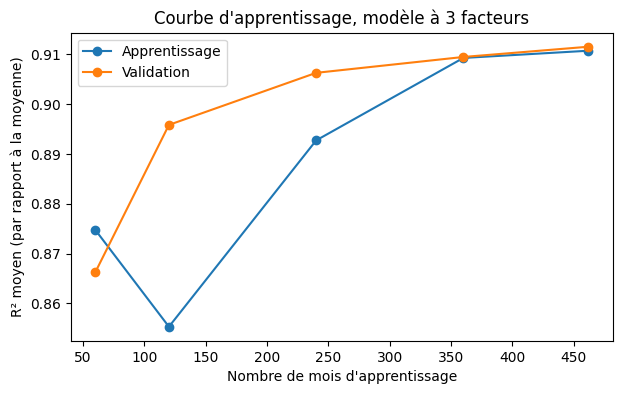

Tailles : [60, 120, 240, 360, 462]
R² apprentissage : [0.875 0.855 0.893 0.909 0.911]
R² validation    : [0.866 0.896 0.906 0.909 0.912]


In [18]:
VAL = 96                                    # derniers 96 mois de l'apprentissage = bloc de validation
Xs, Ys = X_tr.iloc[:-VAL], Y_tr.iloc[:-VAL]
Xv, Yv = X_tr.iloc[-VAL:], Y_tr.iloc[-VAL:]

tailles = [60, 120, 240, 360, len(Xs)]
r2_apprentissage, r2_validation = [], []
for n in tailles:
    Xn, Yn = Xs[COLS3].iloc[-n:], Ys.iloc[-n:]
    pipe = nouveau_modele().fit(Xn, Yn)
    ref = Yn.mean().values
    r2_apprentissage.append(r2_oos(Yn.values, pipe.predict(Xn), np.tile(ref, (len(Yn), 1))))
    r2_validation.append(r2_oos(Yv.values, pipe.predict(Xv[COLS3]), np.tile(ref, (len(Yv), 1))))

plt.figure(figsize=(7, 4))
plt.plot(tailles, r2_apprentissage, marker='o', label="Apprentissage")
plt.plot(tailles, r2_validation, marker='o', label="Validation")
plt.xlabel("Nombre de mois d'apprentissage"); plt.ylabel("R² moyen (par rapport à la moyenne)")
plt.title("Courbe d'apprentissage, modèle à 3 facteurs"); plt.legend()
plt.savefig("figures/fig4_apprentissage.png", dpi=150, bbox_inches='tight')
plt.show()
print("Tailles :", tailles)
print("R² apprentissage :", np.round(r2_apprentissage, 3))
print("R² validation    :", np.round(r2_validation, 3))

In [19]:
pipe3 = modeles_ajustes['3 facteurs']
ref_tr = np.tile(Y_tr.mean().values, (len(Y_tr), 1))
print("R² apprentissage :", round(r2_oos(Y_tr.values, pipe3.predict(X_tr[COLS3]), ref_tr), 4))
print("R² test          :", round(tableau.loc['3 facteurs', 'R² test'], 4))

R² apprentissage : 0.9112
R² test          : 0.8996


**Surapprentissage et généralisation.** La courbe d'apprentissage se stabilise à partir d'environ 360 mois : avec 60 mois, le R² de validation est de 0,866, et il atteint 0,909 avec 360 mois puis 0,912 avec 462 mois, où il rejoint le R² d'apprentissage (0,911). Les deux courbes se superposent donc dès 360 mois, ce qui montre que ajouter des données au-delà n'améliore presque plus le modèle et qu'il n'y a pas de surapprentissage. Le seul écart où l'apprentissage dépasse la validation est à 60 mois (0,875 contre 0,866), ce qui est attendu : avec peu de données, 4 paramètres par portefeuille s'ajustent un peu trop au bruit. Entre 120 et 240 mois, le R² de validation est au contraire supérieur à celui d'apprentissage ; ce n'est pas un signe de surapprentissage, et peut s'expliquer par la période concernée (les 120 derniers mois du bloc d'apprentissage incluent la période agitée de la fin des années 1990, plus difficile à expliquer, alors que le bloc de validation, plus récent, est mieux expliqué). Sur l'ensemble de l'apprentissage, le R² est de 0,9112 contre 0,8996 sur le test, soit un écart de seulement 0,012 : le modèle généralise bien à des mois jamais vus. Le faible nombre de paramètres (4 par portefeuille pour 558 mois) limite le risque de surapprentissage. En validation croisée, l'écart-type de 0,058 entre les plis indique un résultat globalement stable, avec un pli plus difficile (0,779) qui correspond à la période agitée de la fin des années 1990 et du début des années 2000.

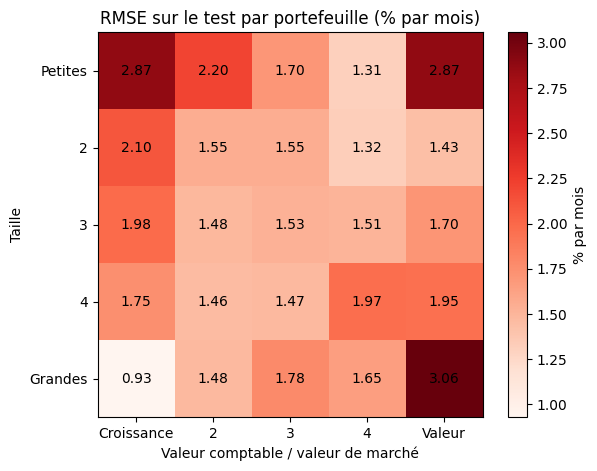

RMSE le plus élevé : BIG HiBM 3.06 %
RMSE le plus faible: BIG LoBM 0.93 %
R² le plus faible  : BIG HiBM 0.802
R² le plus élevé   : BIG LoBM 0.959


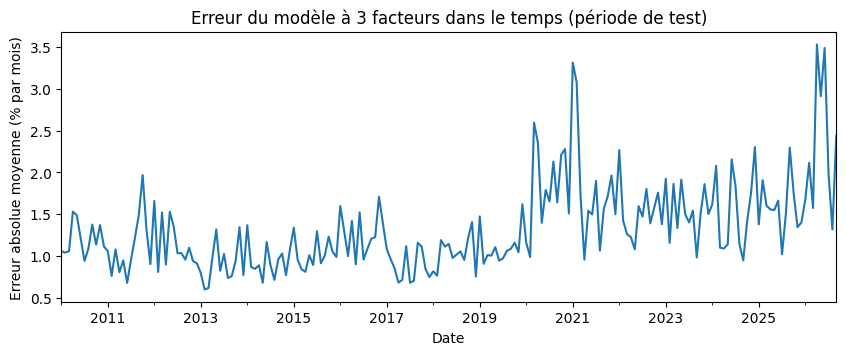


Trois mois les plus mal prédits :
Date
2026-04-01    3.53
2026-06-01    3.49
2021-01-01    3.31
dtype: float64


In [20]:
pred_te = pipe3.predict(X_te[COLS3])
resid_te = Y_te_v - pred_te
ref_te = np.tile(Y_tr.mean().values, (len(Y_te), 1))

# OÙ : RMSE et R² par portefeuille
rmse_p = np.sqrt((resid_te ** 2).mean(axis=0))
r2_p = r2_par_portefeuille(Y_te_v, pred_te, ref_te)

fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(rmse_p.reshape(5, 5), cmap='Reds')
ax.set_xticks(range(5)); ax.set_xticklabels(['Croissance', '2', '3', '4', 'Valeur'])
ax.set_yticks(range(5)); ax.set_yticklabels(['Petites', '2', '3', '4', 'Grandes'])
ax.set_xlabel("Valeur comptable / valeur de marché"); ax.set_ylabel("Taille")
ax.set_title("RMSE sur le test par portefeuille (% par mois)")
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{rmse_p.reshape(5, 5)[i, j]:.2f}", ha='center', va='center')
plt.colorbar(im, label="% par mois")
plt.savefig("figures/fig5_erreurs_portefeuilles.png", dpi=150, bbox_inches='tight')
plt.show()

noms = Y.columns
print("RMSE le plus élevé :", noms[rmse_p.argmax()], round(rmse_p.max(), 2), "%")
print("RMSE le plus faible:", noms[rmse_p.argmin()], round(rmse_p.min(), 2), "%")
print("R² le plus faible  :", noms[r2_p.argmin()], round(r2_p.min(), 3))
print("R² le plus élevé   :", noms[r2_p.argmax()], round(r2_p.max(), 3))

# QUAND : erreur absolue moyenne par mois
err_mois = pd.Series(np.abs(resid_te).mean(axis=1), index=Y_te.index)
plt.figure(figsize=(10, 3.5))
err_mois.plot()
plt.xlabel("Date"); plt.ylabel("Erreur absolue moyenne (% par mois)")
plt.title("Erreur du modèle à 3 facteurs dans le temps (période de test)")
plt.savefig("figures/fig6_erreurs_temps.png", dpi=150, bbox_inches='tight')
plt.show()
print("\nTrois mois les plus mal prédits :")
print(err_mois.sort_values(ascending=False).head(3).round(2))

In [21]:
reg3 = pipe3.named_steps['reg']
coef_df = pd.DataFrame(np.column_stack([reg3.intercept_, reg3.coef_]),
                       index=Y.columns, columns=['alpha', 'beta_Mkt', 's_SMB', 'h_HML']).round(3)
display(coef_df)
coef_df.to_csv("figures/coefficients.csv")

# Illustration sur 5 mois de test, jamais vus à l'apprentissage
j = 0                                              # portefeuille illustré : SMALL LoBM
ex = pd.DataFrame({
    'Mkt-RF': X_te['Mkt-RF'].values[:5], 'SMB': X_te['SMB'].values[:5], 'HML': X_te['HML'].values[:5],
    'Prédit (%)': pred_te[:5, j].round(2), 'Réel (%)': Y_te_v[:5, j].round(2)},
    index=Y_te.index[:5].date)
ex['Écart (%)'] = (ex['Réel (%)'] - ex['Prédit (%)']).round(2)
print("Portefeuille illustré :", Y.columns[j])
display(ex)

,alpha,beta_Mkt,s_SMB,h_HML
SMALL LoBM,-0.478,1.113,1.365,-0.277
ME1 BM2,-0.009,0.970,1.339,0.042
ME1 BM3,-0.039,0.946,1.082,0.322
ME1 BM4,0.165,0.883,1.078,0.444
SMALL HiBM,0.118,0.972,1.078,0.697
ME2 BM1,-0.186,1.135,1.002,-0.380
ME2 BM2,-0.029,1.027,0.916,0.138
ME2 BM3,0.068,0.969,0.740,0.397
ME2 BM4,0.068,0.953,0.706,0.554
ME2 BM5,-0.002,1.081,0.887,0.785


Portefeuille illustré : SMALL LoBM


,Mkt-RF,SMB,HML,Prédit (%),Réel (%),Écart (%)
2010-01-01,-3.35,0.43,0.33,-3.71,-4.31,-0.60
2010-02-01,3.39,1.18,3.18,4.02,4.17,0.15
2010-03-01,6.30,1.46,2.19,7.92,6.98,-0.94
2010-04-01,1.99,4.84,2.96,7.52,6.51,-1.01
2010-05-01,-7.90,0.13,-2.48,-8.41,-7.10,1.31


**Analyse des erreurs.**
- **Où.** Sur le test, le RMSE du modèle à 3 facteurs va de 0,93 % par mois (BIG LoBM, grandes entreprises de croissance) à 3,06 % (BIG HiBM, grandes entreprises de valeur). Les deux autres coins de la grille sont aussi mal expliqués : SMALL LoBM et SMALL HiBM (2,87 % chacun). À l'inverse, le centre de la grille (tailles 2 à 4, valeurs 2 à 4) reste entre 1,3 % et 2,0 %. Les portefeuilles situés aux extrêmes de taille et de valeur sont donc les plus difficiles à expliquer avec trois facteurs. Hypothèse, non testée ici : les petites entreprises sont plus sensibles à des chocs qui leur sont propres, et les grandes entreprises de valeur sont concentrées dans quelques secteurs dont les chocs ne sont pas captés par HML, construit sur l'ensemble des tailles.
- **Quand.** Avant 2019, l'erreur absolue moyenne reste autour de 1 % par mois. Elle monte à partir de 2020 : pic d'environ 2,6 % début 2020 (cohérent avec la crise du COVID-19), puis 3,31 % en janvier 2021. Les trois mois les plus mal prédits sont avril 2026 (3,53 %), juin 2026 (3,49 %) et janvier 2021 (3,31 %). [À compléter avec la cellule 35 bis : valeurs de Mkt-RF, SMB et HML ces mois-là et événement de marché correspondant, avec sa source ; si tu n'en trouves pas, écris « aucun événement identifié ».] Le modèle explique donc moins bien les périodes de stress ou de rotation brutale entre styles.

**Coefficients.** Les bêtas de marché sont tous proches de 1 (de 0,88 pour ME1 BM4 à 1,16 pour ME4 BM5). Le coefficient s sur SMB diminue avec la taille : de 1,08 à 1,37 pour les plus petites entreprises à −0,25 à −0,16 pour les plus grandes. Le coefficient h sur HML augmente avec le ratio valeur comptable / valeur de marché : de −0,43 à −0,28 pour les titres de croissance à 0,70 à 0,82 pour les titres de valeur. Les facteurs captent donc bien la structure de la grille 5×5. Côté alphas, 19 des 25 ont une valeur absolue inférieure à 0,15 % par mois. Le plus éloigné de zéro est SMALL LoBM (−0,478 % par mois, soit environ −5,7 % par an) : les petites entreprises de croissance ont rapporté nettement moins que ne l'exigent leurs trois expositions. Ce sont des associations statistiques, pas des relations de cause à effet.

**Illustration sur mois non vus** (portefeuille SMALL LoBM, janvier à mai 2010, hors apprentissage). Le modèle prédit le bon signe les 5 mois. L'écart (réel − prédit) va de −1,01 % à +1,31 %, soit un écart absolu moyen d'environ 0,80 %. Par exemple en mai 2010 : le marché perd 7,90 %, le modèle prédit −8,41 % et le réel est −7,10 %, donc le modèle exagère légèrement la baisse. Ces écarts sont inférieurs au RMSE de ce portefeuille sur tout le test (2,87 %), car 2010 est une période où l'erreur moyenne est faible (graphique des erreurs dans le temps).

## 8. Analyse critique
- **Explication, pas prévision.** Le modèle relie le rendement d'un mois aux facteurs du même mois, qui ne sont connus qu'après coup. Il explique les rendements, il ne les prévoit pas. De plus, SMB et HML sont construits à partir de portefeuilles proches de ceux étudiés, ce qui gonfle mécaniquement le R² (0,90).
- **Alphas.** Le test GRS rejette l'hypothèse d'alphas nuls (p < 0,0001), même si l'alpha moyen absolu n'est que de 0,097 % par mois. Il est très puissant avec 558 mois, et suppose des erreurs de variance constante, ce qui n'est qu'approximatif : le graphique des facteurs montre des périodes agitées et calmes. Le GRS a été calculé sur l'apprentissage seulement.
- **Une seule coupure.** Un seul découpage (apprentissage jusqu'en 2009, test 2010-2026), choisi par moi. L'erreur augmente à partir de 2020 : la stabilité des coefficients après 2020 n'est pas démontrée. L'OLS est déterministe, donc tester d'autres graines n'a pas de sens ; la stabilité a été vérifiée par validation chronologique à 5 plis (écart-type 0,058 sur le R²).
- **Données.** Actions américaines uniquement, rendements pondérés par la capitalisation, séries révisées par les auteurs depuis leur publication (j'utilise la version actuelle). Les valeurs extrêmes (krach de 1987, crise de 2008, 2020) ont été conservées, et pèsent lourd dans les moindres carrés. Une corrélation ne prouve pas une causalité.
- **Pistes concrètes.** (1) Modèle à 5 facteurs (ajout de RMW et CMA) pour réduire l'alpha des petites entreprises de croissance. (2) Estimer les coefficients sur fenêtre glissante pour tester leur stabilité dans le temps. (3) Refaire le GRS sur la période de test et avec une version robuste à l'hétéroscédasticité. (4) Essayer d'autres dates de coupure, par exemple 2000 ou 2015.

## 9. Conclusion
Oui, le modèle à trois facteurs explique mieux les rendements des 25 portefeuilles que le CAPM et que la moyenne historique : son R² hors échantillon est de 0,8996 sur 2010-2026 (objectif > 0,80 atteint), contre 0,7165 pour le CAPM, et son RMSE de 1,85 % par mois contre 3,21 % (CAPM) et 5,81 % (moyenne). Les alphas ne sont en revanche pas conjointement nuls (GRS, p < 0,0001) : le modèle est très bon mais pas complet, surtout pour les petites entreprises de croissance (alpha de −0,478 % par mois pour SMALL LoBM). Il explique les rendements du même mois, il ne les prévoit pas.

## 10. Références et reproduction
- Fama, E. F. et French, K. R. (1993), « Common risk factors in the returns on stocks and bonds », *Journal of Financial Economics*, 33(1), 3-56.
- Kenneth R. French Data Library : https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html (extraction du 17/11/2026).
- Support de cours Tp_ML.ipynb (régression linéaire, `LinearRegression`).
- Dépôt GitHub : https://github.com/TON-IDENTIFIANT/CODEAPOGEE-NOM-GROUPE
- **Reproduction** : Python 3.13.18, numpy 2.4.6, pandas 2.2.3, scikit-learn 1.6.1 (versions affichées par la cellule de configuration). Cloner le dépôt, `pip install -r requirements.txt`, ouvrir `notebooks/projet_F28.ipynb`, puis « Redémarrer et tout exécuter » (le notebook relit `data/raw/` ; graine = 42).

## Déclaration des ressources et outils d'IA
| Outil ou ressource | Version ou date | Usage précis | Parties concernées | Vérification effectuée |
|---|---|---|---|---|
| Claude (assistant d'IA, Anthropic) | 17/11/2026 | Explication du modèle de Fama-French, suggestion du code (chargement, graphiques, pipeline, test GRS, validation), aide à la rédaction du compte rendu | Notebook, sections 1 à 10 | Code lu, exécuté et adapté ; sorties vérifiées ; tous les chiffres du compte rendu recopiés depuis les sorties du notebook |
| Support de cours Tp_ML.ipynb | - | Syntaxe de `LinearRegression`, métriques | Sections 5 à 7 | Reprise du schéma `fit` / `predict` |
| Documentation pandas, scikit-learn, scipy | - | Fonctions utilisées | Notebook | - |